# Задание 2.2
## Уравнение $z^8=1+i$

### Условие:
Решите уравнение и изобразите множество решений на комплексной плоскости:
$$
z^8=1+i.
$$

### Теория:
Если $w=\rho e^{i\theta}\neq0$, то уравнение $z^n=w$ имеет ровно $n$ различных корней
$$
z_k=\sqrt[n]{\rho}\;e^{\,i\frac{\theta+2\pi k}{n}},\qquad k=0,1,\dots,n-1,
$$
которые лежат на окружности радиуса $\sqrt[n]{\rho}$ и являются вершинами правильного $n$-угольника.

### Решение:
Правая часть: $1+i=\sqrt2\,e^{i\pi/4}$, то есть $\rho=\sqrt2$, $\theta=\dfrac\pi4$. При $n=8$:
$$
|z|=(\sqrt2)^{1/8}=2^{1/16}\approx1{,}0443,\qquad
\arg z_k=\frac{\pi/4+2\pi k}{8}=\frac{\pi}{32}+\frac{\pi k}{4}.
$$
Итак,
$$
z_k=2^{1/16}\exp\!\Bigl(i\Bigl(\frac{\pi}{32}+\frac{\pi k}{4}\Bigr)\Bigr),\qquad k=0,\dots,7.
$$
Соседние корни повёрнуты друг относительно друга на угол $\pi/4$.

In [ ]:
import numpy as np

w = 1 + 1j
rho, theta = abs(w), np.angle(w)
k = np.arange(8)
z = rho**(1/8)*np.exp(1j*(theta + 2*np.pi*k)/8)

print(f'|z| = 2^(1/16) = {rho**(1/8):.6f}')
for kk, zk in zip(k, z):
    print(f'z_{kk} = {zk.real: .6f} {zk.imag:+.6f}i    arg = {np.degrees(np.angle(zk)):8.3f}°')

|z| = 2^(1/16) = 1.044274
z_0 =  1.039245 +0.102357i    arg =    5.625°
z_1 =  0.662480 +0.807235i    arg =   50.625°
z_2 = -0.102357 +1.039245i    arg =   95.625°
z_3 = -0.807235 +0.662480i    arg =  140.625°
z_4 = -1.039245 -0.102357i    arg = -174.375°
z_5 = -0.662480 -0.807235i    arg = -129.375°
z_6 =  0.102357 -1.039245i    arg =  -84.375°
z_7 =  0.807235 -0.662480i    arg =  -39.375°


### Проверка: $z_k^8=1+i$ для всех $k$

In [2]:
print(np.round(z**8, 12))
print('все z_k^8 = 1+i:', np.allclose(z**8, w))

[1.+1.j 1.+1.j 1.+1.j 1.+1.j 1.+1.j 1.+1.j 1.+1.j 1.+1.j]
все z_k^8 = 1+i: True


### Изображение на комплексной плоскости

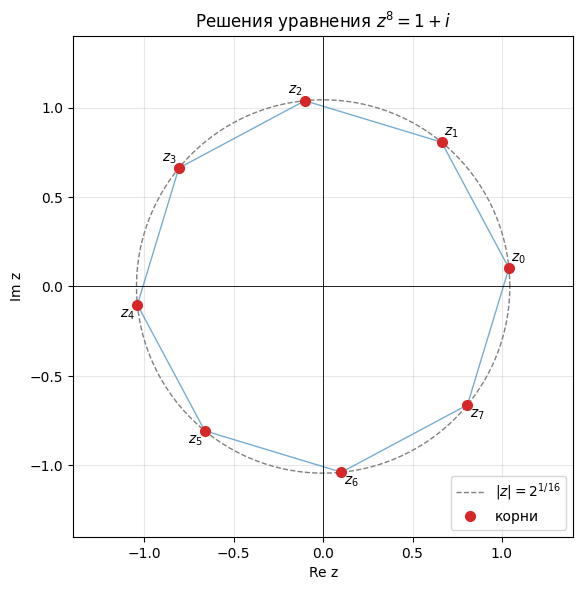

In [3]:
import matplotlib.pyplot as plt

R = rho**(1/8)
t = np.linspace(0, 2*np.pi, 400)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.plot(R*np.cos(t), R*np.sin(t), '--', color='gray', lw=1, label=r'$|z|=2^{1/16}$')
ax.plot(np.append(z.real, z[0].real), np.append(z.imag, z[0].imag), '-', color='tab:blue', lw=1, alpha=0.6)
ax.plot(z.real, z.imag, 'o', color='tab:red', ms=7, label='корни')
for kk, zk in zip(k, z):
    ax.annotate(f'$z_{kk}$', (zk.real, zk.imag), xytext=(7*np.sign(zk.real), 7*np.sign(zk.imag)),
                textcoords='offset points', ha='center', va='center')
ax.axhline(0, color='k', lw=0.6); ax.axvline(0, color='k', lw=0.6)
ax.set_aspect('equal'); ax.grid(alpha=0.3)
ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)
ax.set_xlabel('Re z'); ax.set_ylabel('Im z')
ax.set_title(r'Решения уравнения $z^8=1+i$')
ax.legend(loc='lower right')
plt.show()

### Ответ:

$$
z_k=\sqrt[16]{2}\,\Bigl(\cos\bigl(\tfrac{\pi}{32}+\tfrac{\pi k}{4}\bigr)+i\sin\bigl(\tfrac{\pi}{32}+\tfrac{\pi k}{4}\bigr)\Bigr),\quad k=0,1,\dots,7.
$$
Восемь точек — вершины правильного восьмиугольника, вписанного в окружность радиуса $2^{1/16}$, первая вершина имеет аргумент $\pi/32$.